# Titanic Survival Prediction with Logistic Regression
**Team no.:** ___  |  **Repo:** ___

# Section 1: Problem, Dataset and EDA
*Owner: Documentation lead*

## 1.1 Problem statement and motivation
**Problem:** Given details about a Titanic passenger (class, sex, age, family aboard, fare, port), predict whether the passenger **survived (1)** or **did not survive (0)**.

**Why logistic regression?** The answer is a category (0 or 1), not a number, so this is a **classification** problem. Logistic regression outputs the probability of class 1 and turns it into a 0/1 prediction.

**Motivation:** *(rewrite in your own words: why is this problem interesting? What can it tell us about who had a better chance of survival?)*

## 1.2 Dataset description
- **Source:** Kaggle, *Titanic Dataset* by yasserh (https://www.kaggle.com/datasets/yasserh/titanic-dataset)
- **File in repo:** `data/Titanic-Dataset.csv`
- **Target column:** `Survived` (0 = No, 1 = Yes)

| Column | Meaning |
|---|---|
| PassengerId | Row number (identifier) |
| Survived | Target: 0 = No, 1 = Yes |
| Pclass | Ticket class (1 = 1st, 2 = 2nd, 3 = 3rd) |
| Name | Passenger name |
| Sex | male / female |
| Age | Age in years |
| SibSp | Number of siblings or spouses aboard |
| Parch | Number of parents or children aboard |
| Ticket | Ticket number |
| Fare | Fare paid |
| Cabin | Cabin number |
| Embarked | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

*(After running the cells below, check this table against the real columns and fix anything that differs.)*

### Import the tools

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("outputs", exist_ok=True)   # plots are saved here

### Load the data
`pd.read_csv` reads the CSV into a table (DataFrame). Always use a **relative path** so it works on every laptop.

In [2]:
df = pd.read_csv("data/Titanic-Dataset.csv")

print("Rows, columns:", df.shape)
print("Column names:", df.columns.tolist())
df.head()

Rows, columns: (891, 12)
Column names: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Data types and summary statistics
`info()` shows each column's type and how many values are filled. `describe()` gives mean, min, max and so on for numeric columns.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Missing values
Missing values must be handled before training. Count them and see what fraction of each column is empty.

In [5]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_percent})

,missing,percent
PassengerId,0,0.0
Survived,0,0.0
Pclass,0,0.0
Name,0,0.0
Sex,0,0.0
Age,177,19.9
SibSp,0,0.0
Parch,0,0.0
Ticket,0,0.0
Fare,0,0.0


**Observation:** *(fill in after running: which columns have missing values? For example, Age has some missing values and Cabin is mostly empty.)*

### How many passengers survived?
A countplot shows how balanced the two classes are.

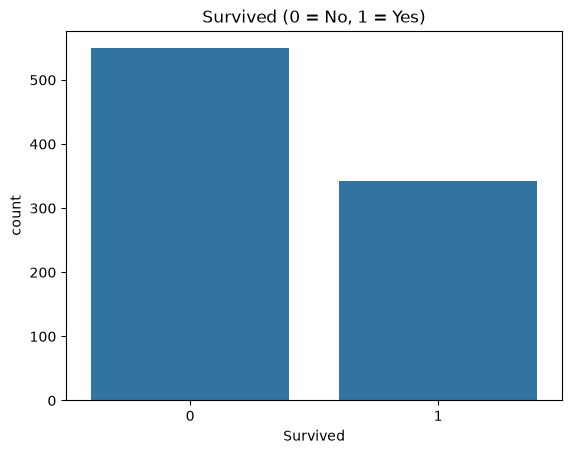

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.62
1    0.38
Name: proportion, dtype: float64


In [6]:
sns.countplot(x="Survived", data=df)
plt.title("Survived (0 = No, 1 = Yes)")
plt.savefig("outputs/survival_count.png", bbox_inches="tight")
plt.show()

print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True).round(2))

### Survival by sex

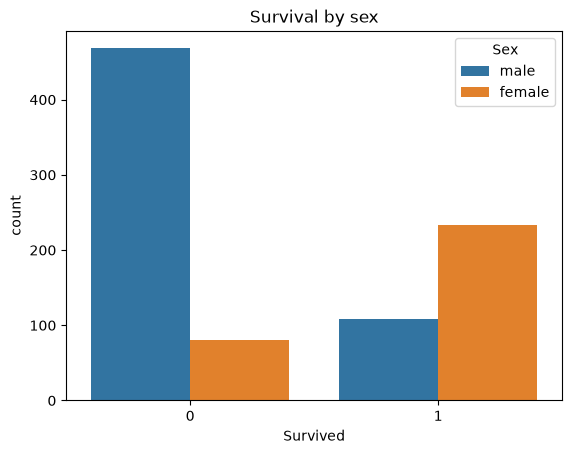

Sex
female    0.74
male      0.19
Name: Survived, dtype: float64


In [7]:
sns.countplot(x="Survived", hue="Sex", data=df)
plt.title("Survival by sex")
plt.savefig("outputs/survival_by_sex.png", bbox_inches="tight")
plt.show()

print(df.groupby("Sex")["Survived"].mean().round(2))

### Survival by ticket class

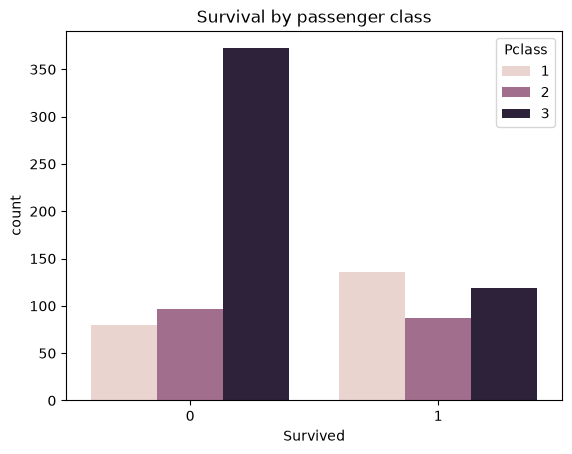

Pclass
1    0.63
2    0.47
3    0.24
Name: Survived, dtype: float64


In [8]:
sns.countplot(x="Survived", hue="Pclass", data=df)
plt.title("Survival by passenger class")
plt.savefig("outputs/survival_by_class.png", bbox_inches="tight")
plt.show()

print(df.groupby("Pclass")["Survived"].mean().round(2))

### Age and survival

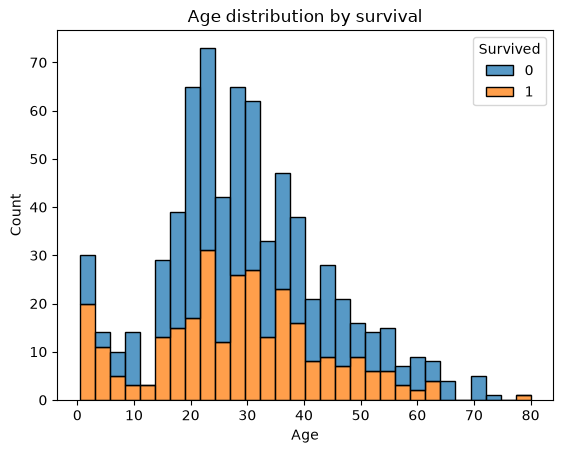

In [9]:
sns.histplot(data=df, x="Age", hue="Survived", bins=30, multiple="stack")
plt.title("Age distribution by survival")
plt.savefig("outputs/age_by_survival.png", bbox_inches="tight")
plt.show()

### EDA findings
Write 3 to 4 sentences using the numbers printed above. For example:
- Which sex had the higher survival rate?
- Which class had the highest and lowest survival rate?
- Were children more likely to survive?
- Is the target balanced?

*These findings go on slide 2 and in the video.*

# Section 2: Preprocessing and Train/Test Split
*Owner: Execution lead*

**Goal:** turn the raw table into clean, numeric, scaled data and split it for training and testing.

**This section hands over these variables** (the next sections depend on the exact names):
`X_train`, `X_test`, `y_train`, `y_test`, `scaler`

Steps: fill missing values, encode text as numbers, check correlation, select features, split, normalize.

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

os.makedirs("outputs", exist_ok=True)

df = pd.read_csv("data/Titanic-Dataset.csv")
print("Original shape:", df.shape)

Original shape: (891, 12)


## 2.1 Handle missing values
- **Age:** fill with the **median**. The median is not pulled around by very old or very young outliers.
- **Embarked:** fill with the **mode** (the most common port), because it is a category.
- **Cabin:** most values are missing, so we will drop it later instead of filling it.

In [11]:
print("Missing values BEFORE:")
print(df[["Age", "Embarked", "Cabin"]].isnull().sum())

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("\nMissing values AFTER (Cabin left for now):")
print(df[["Age", "Embarked", "Cabin"]].isnull().sum())

Missing values BEFORE:
Age         177
Embarked      2
Cabin       687
dtype: int64

Missing values AFTER (Cabin left for now):
Age           0
Embarked      0
Cabin       687
dtype: int64


## 2.2 Encode text columns as numbers
Models only understand numbers.
- **Sex:** male = 0, female = 1 (only two values, so a simple map works).
- **Embarked:** three ports with no natural order, so we use **one-hot encoding** (`get_dummies`): a separate 0/1 column per port. `drop_first=True` removes one column because it can be worked out from the others.

In [12]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True, dtype=int)

df[["Sex", "Embarked_Q", "Embarked_S"]].head()

,Sex,Embarked_Q,Embarked_S
0,0,0,1
1,1,0,0
2,1,0,1
3,1,0,1
4,0,0,1


## 2.3 Correlation
Correlation (from -1 to +1) shows how strongly two columns move together. We look at the **Survived** row to see which columns relate to survival. Name, Ticket and Cabin are text, so `select_dtypes` leaves them out automatically.

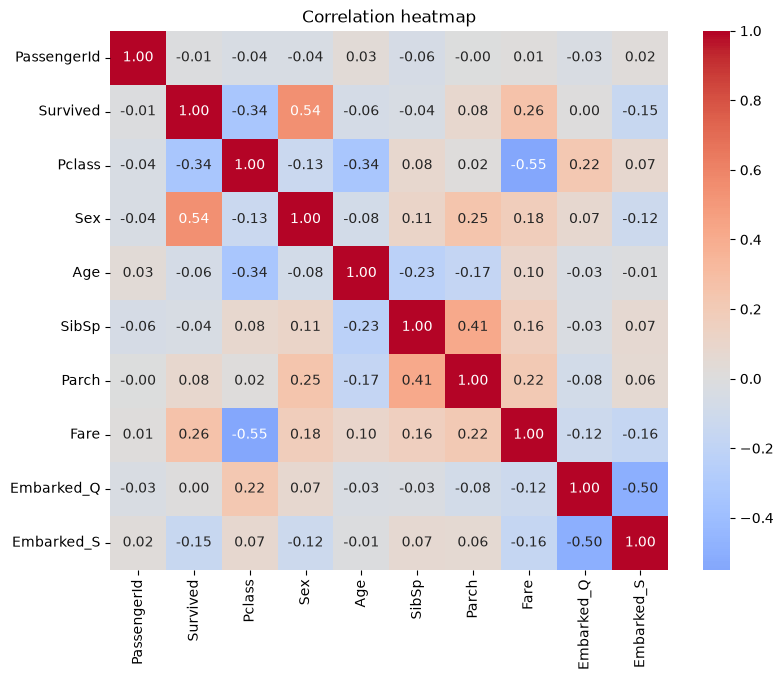

Pclass        -0.338481
Embarked_S    -0.149683
Age           -0.064910
SibSp         -0.035322
PassengerId   -0.005007
Embarked_Q     0.003650
Parch          0.081629
Fare           0.257307
Sex            0.543351
Survived       1.000000
Name: Survived, dtype: float64

In [13]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 7))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.savefig("outputs/correlation_heatmap.png", bbox_inches="tight")
plt.show()

numeric_df.corr()["Survived"].sort_values()

**Observation:** *(fill in from the numbers above: which columns correlate most with Survived? Sex and Pclass are usually the strongest. Notice PassengerId has almost no correlation.)*

## 2.4 Feature selection
We keep columns that carry useful information and drop the rest:

| Dropped | Reason |
|---|---|
| PassengerId | Just a row number, no relation to survival |
| Name | Unique text per person, not usable by a simple model |
| Ticket | Mostly unique codes |
| Cabin | Most values missing |

**Kept:** Pclass, Sex, Age, SibSp, Parch, Fare, Embarked_Q, Embarked_S.

In [14]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

print("Shape after selection:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
df.head()

Shape after selection: (891, 9)
Remaining missing values: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


## 2.5 Split inputs and answer, then train/test split
- `X` = input columns, `y` = the answer (`Survived`).
- 80% of passengers for training, 20% kept for testing.
- `random_state=42`: the same split every time, so everyone gets the same results.
- `stratify=y`: keeps the survived/not-survived ratio equal in train and test.

In [15]:
X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training passengers:", len(X_train))
print("Testing passengers: ", len(X_test))
print("Survival rate in train:", round(y_train.mean(), 3))
print("Survival rate in test: ", round(y_test.mean(), 3))

Training passengers: 712
Testing passengers:  179
Survival rate in train: 0.383
Survival rate in test:  0.385


## 2.6 Normalization (scaling)
Columns have very different ranges (Fare goes up to hundreds, Sex is 0 or 1). `StandardScaler` rescales each column to mean 0 and standard deviation 1 so no column dominates just because its numbers are bigger.

**Important:** the scaler learns (`fit`) from the **training data only**, then is applied (`transform`) to both sets. If it learned from the test data, information from the test set would leak into training.

In [16]:
scaler = StandardScaler()

X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Columns:", X_train.columns.tolist())
print("Train means (should be about 0):", X_train.mean().round(2).tolist())
X_train.head()

Columns: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
Train means (should be about 0): [-0.0, 0.0, 0.0, -0.0, -0.0, -0.0, -0.0, 0.0]


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
692,0.829568,-0.742427,-0.112078,-0.465084,-0.466183,0.513812,-0.289333,0.611978
481,-0.370945,-0.742427,-0.112078,-0.465084,-0.466183,-0.662563,-0.289333,0.611978
527,-1.571457,-0.742427,-0.112078,-0.465084,-0.466183,3.955399,-0.289333,0.611978
855,0.829568,1.346933,-0.879807,-0.465084,0.727782,-0.467874,-0.289333,0.611978
801,-0.370945,1.346933,0.118241,0.478335,0.727782,-0.115977,-0.289333,0.611978


## 2.7 Final check before handing over
Make sure there are no missing values and the shapes match.

In [17]:
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)
print("Missing in X_train:", X_train.isnull().sum().sum())
print("Missing in X_test: ", X_test.isnull().sum().sum())

X_train: (712, 8)  y_train: (712,)
X_test:  (179, 8)  y_test:  (179,)
Missing in X_train: 0
Missing in X_test:  0


# Section 3: Training the Model
*Owner: PPT lead*

**Needs from Section 2:** `X_train`, `X_test`, `y_train`, `y_test`
**Hands over:** `model`, plus the functions `train_model` and `predict`



In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, log_loss

## 3.1 Function to train the model
`LogisticRegression()` creates an empty model and `fit()` learns from the training data. `max_iter=1000` allows enough learning steps to finish.

In [19]:
def train_model(X_train, y_train):
    # Create a logistic regression model and train it on the training data
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    return model

model = train_model(X_train, y_train)
print("Model trained.")

Model trained.


## 3.2 Function to test (predict with) the model
`predict` gives the class (0 or 1). `predict_proba` gives the probability of each class.

In [20]:
def predict(model, X):
    # Returns the predicted class and the probability of survival
    classes = model.predict(X)
    prob_survive = model.predict_proba(X)[:, 1]
    return classes, prob_survive

train_pred, _ = predict(model, X_train)
test_pred, test_prob = predict(model, X_test)

print("First 10 predicted classes:", test_pred[:10])
print("First 10 survival probabilities:", test_prob[:10].round(2))
print("Train accuracy:", round(accuracy_score(y_train, train_pred), 3))
print("Test accuracy: ", round(accuracy_score(y_test, test_pred), 3))

First 10 predicted classes: [0 0 0 0 1 0 1 0 0 0]
First 10 survival probabilities: [0.07 0.05 0.15 0.03 0.68 0.44 0.76 0.33 0.34 0.16]
Train accuracy: 0.808
Test accuracy:  0.804


Train and test accuracy being close means the model is **not overfitting** (it is not just memorizing the training data). *(Comment on your own numbers here.)*

## 3.3 What did the model learn? (coefficients)
Each input column gets a **coefficient**. A positive coefficient pushes the prediction towards survival, a negative one pushes it away. Because the data is scaled, bigger absolute values mean a stronger effect.

Intercept: [-0.657]


,feature,coefficient
0,Pclass,-0.928698
2,Age,-0.502878
3,SibSp,-0.262672
7,Embarked_S,-0.171784
4,Parch,-0.067158
6,Embarked_Q,0.080683
5,Fare,0.099599
1,Sex,1.269598


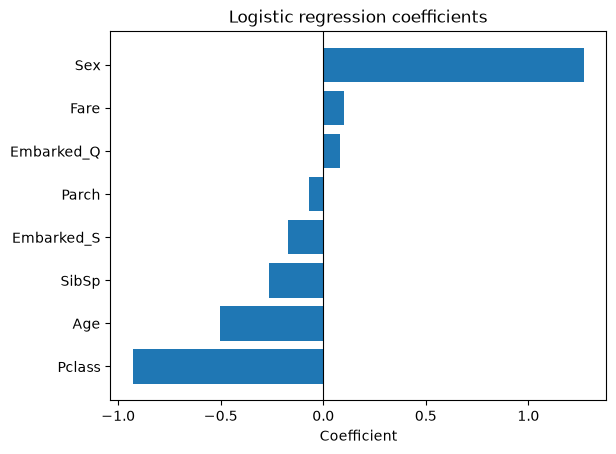

In [21]:
coef_table = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0]
}).sort_values("coefficient")

print("Intercept:", model.intercept_.round(3))
display(coef_table)

plt.barh(coef_table["feature"], coef_table["coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.title("Logistic regression coefficients")
plt.savefig("outputs/coefficients.png", bbox_inches="tight")
plt.show()

**Interpretation:** *(for example: Sex has a large positive coefficient, so being female increases the chance of survival; Pclass is negative, so a higher class number (3rd class) lowers it.)*

## 3.4 Training plot: loss going down
The sklearn `LogisticRegression` learns in one call, so it has no learning curve to draw. To **see** learning, we train the same kind of model (logistic loss) step by step with `SGDClassifier` and record the **log loss** after every epoch. Loss measures how wrong the predicted probabilities are, and lower is better. This model is only used for the plot; the main `model` above is the one we evaluate.

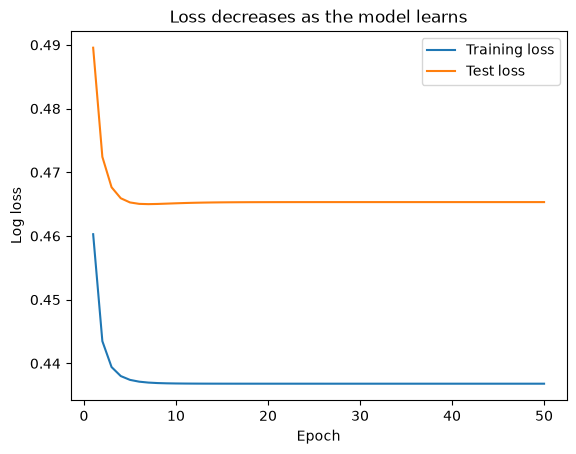

Loss at epoch 1:  0.46
Loss at epoch 50: 0.437


In [22]:
sgd = SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01, random_state=42)

train_losses, test_losses = [], []
for epoch in range(50):
    sgd.partial_fit(X_train, y_train, classes=np.unique(y_train))
    train_losses.append(log_loss(y_train, sgd.predict_proba(X_train)))
    test_losses.append(log_loss(y_test, sgd.predict_proba(X_test)))

plt.plot(range(1, 51), train_losses, label="Training loss")
plt.plot(range(1, 51), test_losses, label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Log loss")
plt.title("Loss decreases as the model learns")
plt.legend()
plt.savefig("outputs/training_loss.png", bbox_inches="tight")
plt.show()

print("Loss at epoch 1: ", round(train_losses[0], 3))
print("Loss at epoch 50:", round(train_losses[-1], 3))

**Interpretation:** *(the loss drops quickly at first and then flattens, meaning the model has learned what it can. Train and test curves staying close means it generalizes well.)*

# Section 4: Evaluation and Interpretation
*Owner: Video lead*

**Needs from earlier sections:** `X_train`, `X_test`, `y_train`, `y_test`, `scaler`, `model`



In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

## 4.1 Evaluation metrics
Treat **survived (1)** as the "positive" class.

- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** of the passengers predicted to survive, how many really survived.
- **Recall:** of the passengers who really survived, how many we found.
- **F1 score:** one number that balances precision and recall.

In [24]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 score": f1_score(y_test, y_pred),
}
for name, value in metrics.items():
    print(f"{name:10s}: {value:.3f}")

Accuracy  : 0.804
Precision : 0.793
Recall    : 0.667
F1 score  : 0.724


## 4.2 Confusion matrix
Rows are the **actual** values and columns are the **predicted** values. The diagonal holds the correct predictions.

[[98 12]
 [23 46]]


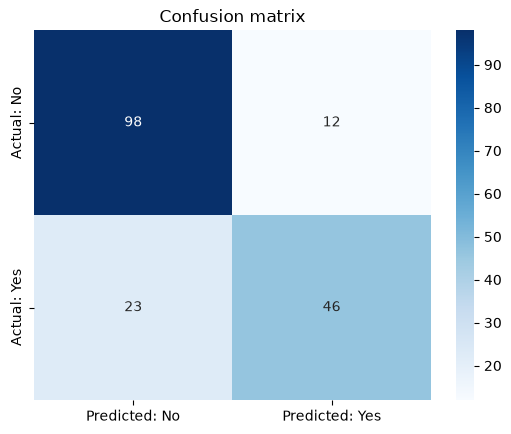

Correctly predicted died: 98, correctly predicted survived: 46
Wrongly predicted survived: 12, wrongly predicted died: 23


In [25]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted: No", "Predicted: Yes"],
            yticklabels=["Actual: No", "Actual: Yes"])
plt.title("Confusion matrix")
plt.savefig("outputs/confusion_matrix.png", bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Correctly predicted died: {tn}, correctly predicted survived: {tp}")
print(f"Wrongly predicted survived: {fp}, wrongly predicted died: {fn}")

## 4.3 Full report

In [26]:
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



## 4.4 ROC curve (optional)
The ROC curve shows how well the model separates the two classes at every possible threshold. The area under it (AUC) is 0.5 for random guessing and 1.0 for a perfect model.

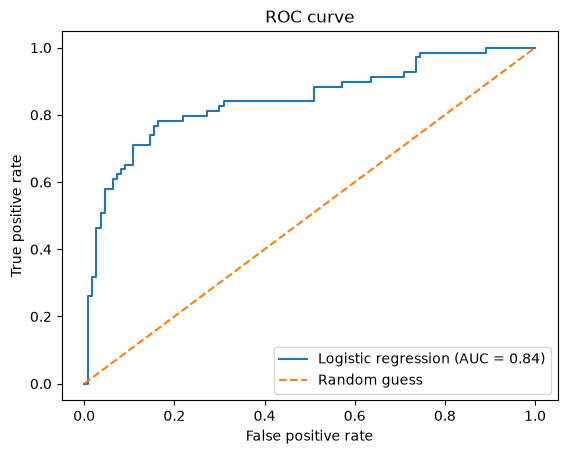

In [27]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.savefig("outputs/roc_curve.png", bbox_inches="tight")
plt.show()

## 4.5 Demo: predict for a new passenger
We enter the raw values for one passenger, in the **same column order** as the training data, apply the **same scaler**, then predict. Try changing the values (for example, a 30-year-old man in 3rd class).

In [28]:
print("Column order:", X_train.columns.tolist())

# Order: Pclass, Sex (0=male, 1=female), Age, SibSp, Parch, Fare, Embarked_Q, Embarked_S
new_passenger = pd.DataFrame(
    [[1, 1, 28, 0, 0, 80.0, 0, 0]],      # TRY IT: change these values
    columns=X_train.columns
)

new_scaled = scaler.transform(new_passenger)
new_scaled = pd.DataFrame(new_scaled, columns=X_train.columns)

predicted_class = model.predict(new_scaled)[0]
probability = model.predict_proba(new_scaled)[0, 1]

print("Predicted class (0 = died, 1 = survived):", predicted_class)
print("Probability of survival:", round(probability, 2))

Column order: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
Predicted class (0 = died, 1 = survived): 1
Probability of survival: 0.96


## 4.6 Interpretation of results
Write this using your own numbers (it is the most important part of the video):

1. **Overall performance:** The model reaches ___% accuracy on unseen passengers.
2. **Errors:** Look at the confusion matrix. Which mistake is more common, predicting survival for someone who died or the reverse? What do precision and recall say about it?
3. **Important features:** Using the coefficients from Section 3, which features matter most and in which direction? Does this match the EDA?
4. **Answer to the problem statement:** Can survival be predicted from these details? What are the limits of the model (few features, simple linear model, small dataset)?
5. **Possible improvements:** More features (for example, titles from names), other models, or tuning.